# Example 5: Multi-page plan

The drawing from papermodels' Example 5: a rotated, multi-page plan in which a column above
(`CPL0.4`) transfers to `FB0.2` rather than to every element it touches. The sheet has two plans
side by side: the lower level on the left and the upper level on the right.

The PDF (37 MB) is not copied into this repository. Set `PAPERMODELS_EXAMPLES` to the
papermodels `Examples` directory, or keep papermodels next to loadtracer.

In [1]:
%matplotlib inline
import sys
import warnings
from decimal import Decimal

import pandas as pd
from papermodels.datatypes.geometry_graph import GeometryGraph
from papermodels.datatypes.joist_models import JoistArrayModel
from loadtracer.load_tracer import LoadTracer

sys.path.insert(0, "..")
from helpers import (
    bottom_members,
    compare_modes,
    load_check,
    load_table,
    occupancies_in,
    quietly,
    reaction_table,
)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_rows = 40

## 1. Build the graph (papermodels)

In [2]:
import os
import pathlib

examples = pathlib.Path(os.environ.get("PAPERMODELS_EXAMPLES", "../../../papermodels/Examples"))
pdf_path = examples / "Example 5" / "multi-page-plan.pdf"
if not pdf_path.exists():
    raise FileNotFoundError(
        f"{pdf_path} not found. Set PAPERMODELS_EXAMPLES to the papermodels Examples directory."
    )

In [3]:
graph = GeometryGraph.from_pdf_file(pdf_path, scale=Decimal(1 / 72 * 4))
graph.assign_collector_behaviour(JoistArrayModel, spacing=1.0)

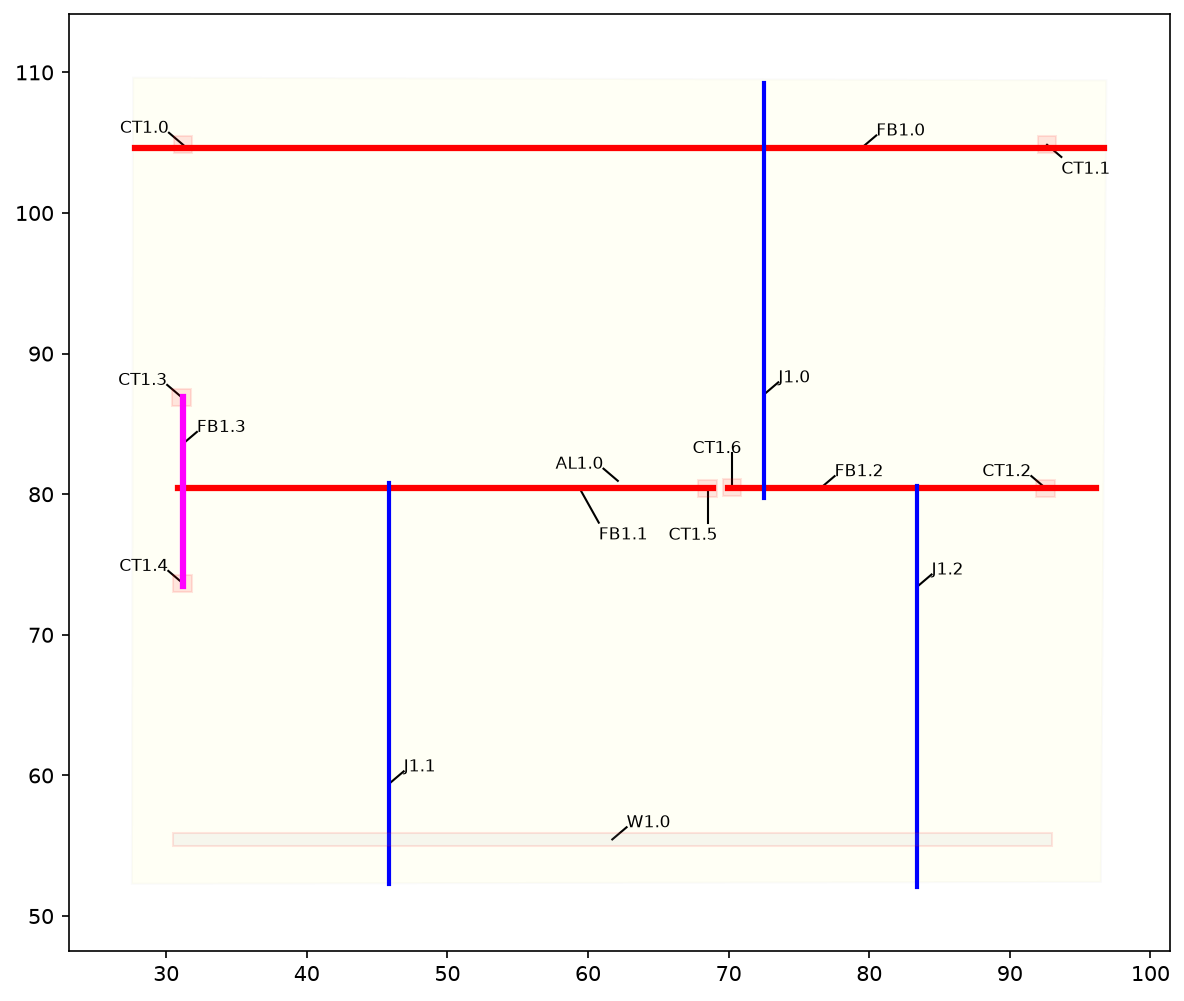

In [4]:
graph.plot_annotations(1)

## 2. Occupancies

loadtracer needs the loads of each occupancy in the drawing, as pressures by load case.
These are the occupancies that the loading areas use:

In [5]:
occupancies_in(graph)

['e', 'f']

The legend of this drawing names its two area loads only "E" (on the lower level) and "F" (on
the upper level). Here `e` is loaded as a residential floor and `f` as a roof. The drawing is in
feet, so these pressures (psf) give loads in lb/ft and lb.

In [6]:
occupancies = {
    "e": {"D": 15.0, "L": 40.0},  # lower level: residential floor
    "f": {"D": 20.0, "S": 35.0},  # upper level: roof
}

## 3. Run loadtracer

Every element is analysed from the top of the graph down. Only the graph and the occupancies
are needed; element heights and floor elevations are not inputs. `artifacts/` receives the
analysis models (`models.json`) and the reactions (`reaction_forces.json`).

In [7]:
lt = LoadTracer(geometry_graph=graph, occupancies=occupancies)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    quietly(lt.execute_analyses, artifacts_dir="artifacts")

print(f"{len(lt.reactions)} members analysed, {len(lt.errors)} errors")
for w in caught:
    print(f"{type(w.message).__name__}: {w.message}")

131 members analysed, 0 errors


All of the load applied to the building reaches the bottom of the graph:

In [8]:
load_check(lt)

,applied,at the bottom
D,"23,103.27","23,103.27"
L,"30,756.39","30,756.39"
S,"20,246.84","20,246.84"


`lt.issues` lists input that loadtracer corrected so that the rundown could continue
(for example, load drawn past the end of a member, which is moved to the member end):

In [9]:
{tag: issues for tag, issues in lt.issues.items()}

{'J0.0-1': ['0.002 of the distributed load from an occupancy (D) extends past the member end at 12.068; its load was applied as a point load at the end.',
  '0.002 of the distributed load from an occupancy (L) extends past the member end at 12.068; its load was applied as a point load at the end.'],
 'J0.0-2': ['0.002 of the distributed load from an occupancy (D) extends past the member end at 12.065; its load was applied as a point load at the end.',
  '0.002 of the distributed load from an occupancy (L) extends past the member end at 12.065; its load was applied as a point load at the end.'],
 'J0.0-3': ['0.002 of the distributed load from an occupancy (D) extends past the member end at 12.061; its load was applied as a point load at the end.',
  '0.002 of the distributed load from an occupancy (L) extends past the member end at 12.061; its load was applied as a point load at the end.'],
 'J0.0-4': ['0.002 of the distributed load from an occupancy (D) extends past the member end at 1

## 4. One member, end to end: `FB0.2`

`FB0.2` receives a point load from the beam `FB0.0` and one from the column `CPL0.4` on the
level above. No joist array bears on it, so it has no converted joist loads:

In [10]:
pd.DataFrame(lt.converted_joist_loads("FB0.2"))

""


The loads on `FB0.2` after expansion, by load case:

In [11]:
load_table(lt, "FB0.2")

,kind,source,case,start,end,w_start / P,w_end,total,profile
0,point,FB0.0,D,4.75,4.75,500.74,None,500.74,
1,point,FB0.0,L,4.75,4.75,"1,335.30",None,"1,335.30",
2,point,CPL0.4,D,4.77,4.77,"1,518.09",None,"1,518.09",
3,point,CPL0.4,S,4.77,4.77,"2,656.65",None,"2,656.65",


The loads in the Pynite model of `FB0.2`:

In [12]:
member = lt.models["FB0.2"]["members"]["FB0.2"]
pd.DataFrame(member["DistLoads"] + member["PtLoads"])

,0,1,2,3
0,FY,500.74,4.75,D
1,FY,"1,335.30",4.75,L
2,FY,"1,518.09",4.77,D
3,FY,"2,656.65",4.77,S


The reactions of `FB0.2` (positive downwards on the supports):

In [13]:
reaction_table(lt, ["FB0.2"])

D      L        S
member support                         
FB0.2  0       1,007.97 669.54 1,324.56
       1       1,010.86 665.76 1,332.09

## 5. Joist loads as point loads or distributed loads

With `joist_loads="point"` each joist reaction is applied as a point load, which is the most
detailed representation. The total load is the same either way. Individual reactions are the
same for uniform joist reactions and differ more the more the joist reactions vary; arrays that
vary by 2:1 or more are listed in the warnings in section 3. For those, check the point load
results.

In [14]:
lt_point = LoadTracer(geometry_graph=graph, occupancies=occupancies, joist_loads="point")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    quietly(lt_point.execute_analyses)

pd.concat({"point": load_check(lt_point)["at the bottom"], "distributed": load_check(lt)["at the bottom"]}, axis=1)

,point,distributed
D,"23,103.27","23,103.27"
L,"30,756.39","30,756.39"
S,"20,246.84","20,246.84"


In [15]:
compare_modes(lt_point, lt, ["FB0.2"])

point                 distributed                  \
                      D      L        S           D      L        S   
member support                                                        
FB0.2  0       1,005.41 662.96 1,324.40    1,007.97 669.54 1,324.56   
       1       1,008.31 659.22 1,331.93    1,010.86 665.76 1,332.09   

               difference            
                        D    L    S  
member support                       
FB0.2  0             2.56 6.58 0.16  
       1             2.54 6.54 0.16

## 6. Reactions at the bottom

The loads delivered to the elements at the bottom of the graph (the foundation):

In [16]:
reaction_table(lt, bottom_members(lt))

,,D,L,S
member,support,,,
W0.0,0,"1,656.41","4,417.09",0.00
CPL0.1,0,316.73,0.00,554.29
CPL0.2,0,"1,737.04",0.00,"3,039.83"
W0.1,0,"5,947.60","8,211.85","5,019.27"
W0.2,0,"1,583.95","1,520.65","1,773.98"
CPL0.6,0,572.47,0.00,"1,001.83"
CPL0.5,0,544.50,0.00,952.88
CT0.2,0,440.15,442.14,480.10
CT0.3,0,554.39,536.08,618.38
